## Assigment 1
#### Programming in Python: Standard and External Library Packages D0040E 27043 HT2026
#### Inés Díaz

First, import libraries, load and explore the data:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
# Load an explore the data
data = pd.read_csv("housing.csv", sep=',')
print(data.head())
data.info()

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data colum

**1. How many geographical units are there in the dataset?**
I consider geographical units unique combinations of lat and len

In [5]:
unique_units = data[['longitude','latitude']].drop_duplicates() # get only lon and lat columns and remove duplicate rows
answer_1 = len(unique_units)
print(f'There are {answer_1} geographical units in the dataset.')

There are 12590 geographical units in the dataset.


**2. What is the mean house value among all “Ocean_proximity” categories?**

In [6]:
housev_mean = data[['median_house_value']].mean()
answer_2 = housev_mean.iloc[0].round(2)
print(f'The mean house value among all "Ocean proximity" categories is {answer_2}.')

The mean house value among all "Ocean proximity" categories is 206855.82.


**3. What is the mean house value in each “Ocean_proximity” category?**

In [7]:
answer_3 = data[['median_house_value', 'ocean_proximity']].groupby(['ocean_proximity']).mean().rename(columns={"median_house_value": "Mean (median) house value"})
print(f'The mean house values in each "Ocean proximity" categories are:\n{answer_3}')

The mean house values in each "Ocean proximity" categories are:
                 Mean (median) house value
ocean_proximity                           
<1H OCEAN                    240084.285464
INLAND                       124805.392001
ISLAND                       380440.000000
NEAR BAY                     259212.311790
NEAR OCEAN                   249433.977427


**4. What can you tell about the differences between the mean and median values?**


The median is less sensitive about outliers, as it is the middle value after sorting

**5. Create histograms for the following columns: “households”, “median_income”, “housing_median_age” and “median_house_value”.**

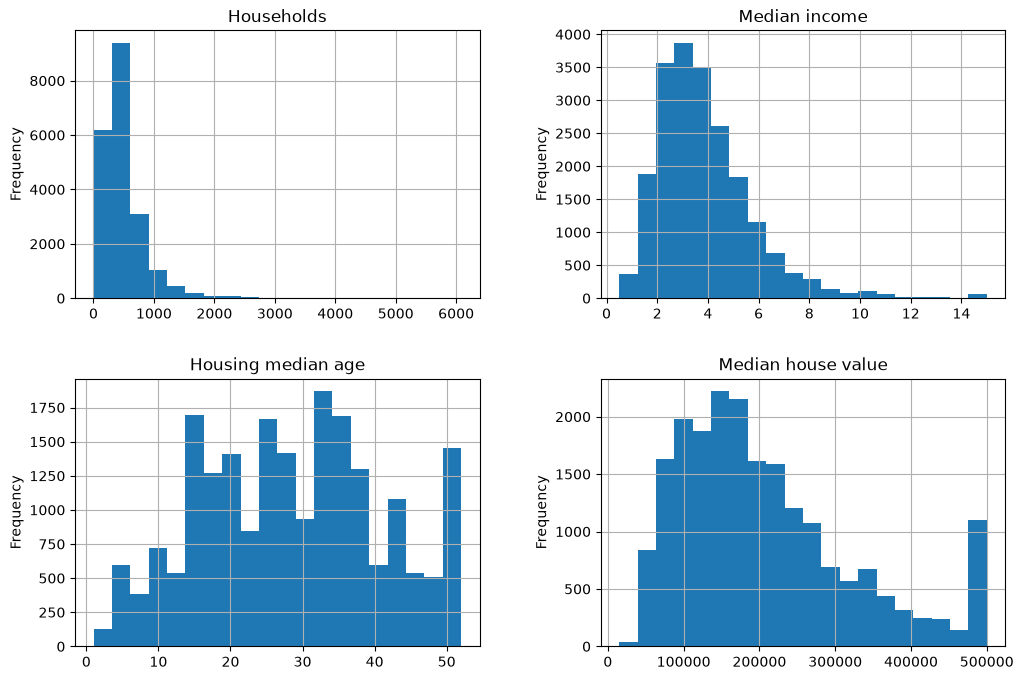

In [8]:
data2 = data[['households', 'median_income', 'housing_median_age', 'median_house_value']].rename(columns={"households": "Households", "median_income": "Median income", "housing_median_age": "Housing median age", "median_house_value": "Median house value"})
axes = data2.hist(bins=20, figsize=(12, 8)) # I found that DataFrame.hist() "calls matplotlib.pyplot.hist() on each series of the df, resulting in one histogram per column" /https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html)
for ax in axes.flatten(): # the array obtained from data2.hist is 2x2, and .flatten() turns it into a 1
    ax.set_ylabel("Frequency")
plt.show()

**6. What can you highlight in these graphs? Specifically focus on end of the “housing_median_age” and “median_house_value” graphs. What do you think about the magnitude of the values in “median_house_value”?**

In the "housing_median_age" histogram, it stands out a spike at the maximum value. This is because all buildings older than (around) 52 are grouped into that single bin. Something similar happens with the "median_house_value", where a similar spike appears before the price of 500000, because gomes worth more are included in that bin. In this second graph, the distribution of the data is heavily skewed to the right with a long tail, so it would be recomendable to transform this variable to work with it.

Regarding the magnitude of the values in "median_house_value", these are in hundreds of thousands of dollars, which is a high scale compared with other variables, so we should be careful when handling them together (for instance, through scaling).

**7. In which category are the most expensive and the largest houses typically located? In which category are the least expensive and smallest houses typically located?**

In [ ]:
# Check the size of the categories
print(data['ocean_proximity'].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


The "ISLAND" category has only a few values, so the metrics will be a bit unreliable.

A proxy for house size could be the number of rooms divided by the number of households:

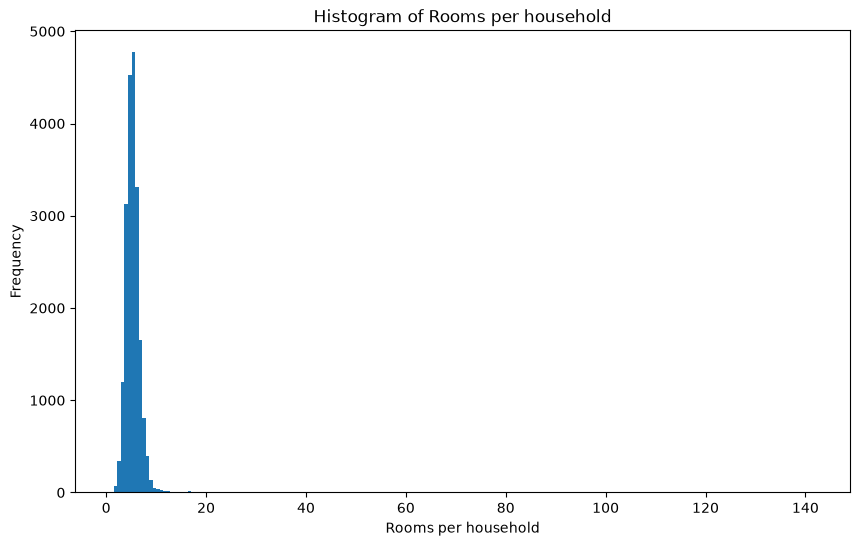

In [28]:
# Create new column with rooms per household and explore the variable
data['rooms_per_household'] = data['total_rooms'] / data['households']
data['rooms_per_household'].plot.hist(bins=200, figsize=(10, 6))
plt.title('Histogram of Rooms per household')
plt.xlabel('Rooms per household')
plt.show()

The variable "rooms_per_household" has some big outliers, while the data in "median_house_value" is skewed to the right as we saw in question 6. Therefore, I'll use the medians to answer the question.

In [31]:
answer_7 = data.groupby('ocean_proximity')[['median_house_value', 'rooms_per_household']].median()
print(f'The median values of price and size of houses per category is:\n {answer_7}')

The median values of price and size of houses per category is:
                  median_house_value  rooms_per_household
ocean_proximity                                         
<1H OCEAN                  214850.0             5.059019
INLAND                     108500.0             5.488421
ISLAND                     414700.0             5.473318
NEAR BAY                   233800.0             5.065781
NEAR OCEAN                 229450.0             5.107957


In [34]:
max_house_value = answer_7['median_house_value'].idxmax()
max_size = answer_7['rooms_per_household'].idxmax()
print(max_house_value)
#print(f'The ')

ISLAND
